# 292. Two short linked HP words instead of one long one: a kill test on Pfam seed pairs

**Result:** not a pass. At 20–30% identity the best linked setting finds 5.6 percentage
points more true pairs than a single 8-letter seed (paired 95% interval 2.4 to 9.4). The
rule asked for 10. Its key also matches by chance about 55 times as often. By the rule this
is neither a pass nor a kill, and the kmerseek index stays as it is.

**Question.** [Notebook 232](232_mismatch_tolerant_seed_extend.ipynb) found that the longest
exact run of matching hydrophobic/polar (HP) classes between true homologs at 20–30%
identity is about 12 residues, so one exact HP word of 20 or more letters rarely survives
between them. Does a key made of two short exact words, each of which only has to survive
6–10 residues, find more true pairs than 232's single 10-letter seed at the same
false-positive rate?

**Words used here**

- *HP alphabet*: each residue is written as H (hydrophobic: `ACFILMVWY`) or P (polar:
  `DEGHKNPQRST`), the 2-letter Thomas–Dill split used in notebooks 230–232
  (`hp_thomas_dill2`). X ends a word.
- *Seed*: a run of aligned columns whose HP classes all match, as a BLAST word hit.
  *Extension*: from the seed, walk along the alignment without gaps, scoring +1 per column
  whose HP classes match and −2 per column where they differ; a gap column stops the walk.
  The seed's score is the best total reached (232's scoring).
- *Anchor*: one short exact HP word (6, 7, 8 or 10 letters) shared by both sequences.
  *Gap*: the number of residues between the end of the first anchor and the start of the
  second, counted in each sequence. *Window*: the largest gap allowed (8, 16 or 32).
- *Key* (a linked word pair; Sahlin 2021 calls it a strobemer, see
  [`292_prior_art.md`](292_prior_art.md)): two anchors plus a gap rule. The gap is stored
  exactly (`exact`: query gap = target gap), stored in 3-residue bins (`binned3`), or not
  stored (`none`: both gaps only have to fit the window, so the key can step over an
  insertion or deletion).
- *How keys are picked*: every anchor pair inside the window (`all`, many keys per
  position), or one partner per position (`rand`): for each first anchor, the second is the
  word in the window with the smallest hash of the two words combined (Sahlin's randstrobe
  rule). Each sequence picks on its own, so the two pick the same partner only when their
  windows agree. One key per position is what an index can afford to store.
- *Comparison*: one query–target pair, real or shuffled, scored only on its own alignment.
  A seed or anchor counts only where it sits on aligned columns, as in 232.
- *Null*: the true pair with the target's residues shuffled along its alignment row (gaps
  stay put, so composition and gap pattern are kept). *Threshold*: the score that 0.1% of
  null comparisons exceed. *False-positive rate (FPR)*: the share of null comparisons above
  the threshold; it is at or below 0.001 here and is printed for every setting.
  *Recall*: the share of true pairs above the threshold. Higher recall is better.
- *B1*: 232's 10-letter seed with extension. *B2*: an 8-letter seed with the same
  extension, so linking is charged against a shorter single seed as well as a longer one.
- *Linked-pair score*: each shared key is extended with the same step from both anchors.
  A key's score is the best total of at most two non-overlapping gap-free segments that
  together contain both anchors. The pair's score is its best key. The no-extension score
  is the number of shared keys.
- *Bootstrap interval*: resample the pairs with replacement 1,000 times, each true pair
  with its own shuffled targets, recompute threshold and recall; the middle 95% of values.
- *Gate 1*: a check, before anything new, that this code reproduces notebook 232's numbers.

**Data, all from notebook 232**

- *True pairs*: 60,000 pairs of Pfam 38.2 seed-alignment members with at least 50 aligned
  columns, sampled from `~/data/pfam/230_pfam_seed_pair_alignments.parquet` (polars sample,
  seed 0). Per identity bin: <20% 6,655; 20–30% 15,130; 30–40% 13,872; 40–60% 16,862;
  ≥60% 7,481. Identity is identical residues over aligned columns; as in 232, a bin
  includes its upper edge (exactly 20% falls in <20%, exactly 60% in 40–60%).
- *Null*: two shuffles per pair, 120,000 null comparisons, 60,000 in each half. That is
  above the 20,000 the 0.001 threshold needs to rest on at least 20 events, so the null was
  not enlarged.
- *Threshold rule*: 232's: the 99.9th percentile of the pooled null scores, taking the
  higher of two neighbouring values; recall counts true pairs scoring strictly above it.

**Rule, fixed before the run** (task brief, 2026-10-14). The setting is chosen on a random
half of the pairs (by recall at 20–30% identity); every reported number comes from the
other half.

- PASS: in the 20–30% identity bin, the chosen linked-pair setting recovers at least 10
  percentage points more true pairs than the better of B1 and B2 at FPR 0.001, and the two
  bootstrap 95% intervals do not overlap.
- KILL: no linked-pair setting beats the better of B1 and B2 in any identity bin outside
  the bootstrap interval.
- Anything else: report, and do not touch the index.

**Decision this informs.** Whether kmerseek's index should store linked HP word pairs
instead of single k-mers. On a pass the next step would be a one-page design note, not
code.

Code: [`linked_pairs_utils.py`](linked_pairs_utils.py) (scoring, tested against brute force
in `tests/test_linked_pairs_utils.py`); scores from
`scripts/linked_pairs_on_alignments.py`; Swiss-Prot key rates from
`scripts/linked_pairs_key_spectrum.py`. No kmerseek run; everything is Python on the
laptop.

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd()))
import hp_conservation_utils as hc
import linked_pairs_utils as lp
import pubfig as pf
import seed_extend_utils as se

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)

FIG = Path("../figures")
SCORES = Path("/Users/olga/data/pfam/292_linked_pairs_scores.parquet")
SPECTRUM = Path("/Users/olga/data/pfam/292_linked_pairs_key_spectrum_swissprot.parquet")
NB232 = Path("/Users/olga/data/pfam/232_seed_extend_scores.parquet")
ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
FPR = 1e-3
N_BOOT = 1000
SPLIT_SEED = 292
SWISSPROT_PROTEINS = (
    572_970  # proteins in uniprot_sprot.fasta.gz, counted by the spectrum script
)
BINS = lp.BINS

# One colour per meaning, kept across all three figures.
COLOR = {
    "B1": pf.OKABE_ITO["blue"],  # 232's 10-residue seed
    "B2": pf.OKABE_ITO["sky_blue"],  # 8-residue seed
    "linked": pf.OKABE_ITO["vermillion"],  # chosen linked pair, with extension
    "linked_count": pf.OKABE_ITO["orange"],  # chosen linked pair, key count only
    "exact": pf.OKABE_ITO["bluish_green"],  # Fig. 3 gap rules
    "binned3": pf.OKABE_ITO["reddish_purple"],
    "none": pf.OKABE_ITO["black"],
}
TREAT_LABEL = {
    "exact": "gap stored exactly",
    "binned3": "gap in 3-residue bins",
    "none": "gap not stored",
}


def plain(setting: str) -> str:
    m, a, g, t = next(x for x in lp.ALL_SETTINGS if lp.setting_name(*x) == setting)
    pick = "every pair of" if m == "all" else "randstrobe pairs of"
    return f"{pick} {a}-letter anchors, gap up to {g}, {TREAT_LABEL[t]}"


MODE_LABEL = {
    "all": "every anchor pair in the window",
    "rand": "one partner per position (randstrobe)",
}

d = hc.add_identity_bin(pl.read_parquet(SCORES))
n_pairs = d.filter(pl.col("kind") == "real").height
print(f"{n_pairs:_} true pairs, {d.height - n_pairs:_} null comparisons")
print(
    d.filter(pl.col("kind") == "real")
    .group_by("identity_bin")
    .len()
    .sort("identity_bin")
)

LINKED = [lp.setting_name(*s) for s in lp.ALL_SETTINGS]
COLS = (
    ["B1_ext", "B2_ext", "seed10_count", "seed8_count"]
    + [f"{s}_ext" for s in LINKED]
    + [f"{s}_count" for s in LINKED]
)

60_000 true pairs, 120_000 null comparisons
shape: (5, 2)
┌──────────────┬───────┐
│ identity_bin ┆ len   │
│ ---          ┆ ---   │
│ enum         ┆ u32   │
╞══════════════╪═══════╡
│ <20%         ┆ 6655  │
│ 20-30%       ┆ 15130 │
│ 30-40%       ┆ 13872 │
│ 40-60%       ┆ 16862 │
│ >=60%        ┆ 7481  │
└──────────────┴───────┘


## 1. Gate 1: notebook 232's baseline, reproduced

B1 rescored from the alignments with this notebook's code, next to the scores 232 stored.
The rule for going on: every per-bin recall equal to 232's.

share of the 180,000 comparisons whose score equals 232's stored score:
shape: (1, 3)
┌──────────┬──────────┬────────┐
│ B1 equal ┆ B2 equal ┆ len    │
│ ---      ┆ ---      ┆ ---    │
│ f64      ┆ f64      ┆ u32    │
╞══════════╪══════════╪════════╡
│ 1.0      ┆ 1.0      ┆ 180000 │
└──────────┴──────────┴────────┘
shape: (5, 5)
┌──────────────┬─────────┬───────────┬─────────┬───────────┐
│ identity_bin ┆ B1 here ┆ B1 in 232 ┆ B2 here ┆ B2 in 232 │
│ ---          ┆ ---     ┆ ---       ┆ ---     ┆ ---       │
│ str          ┆ f64     ┆ f64       ┆ f64     ┆ f64       │
╞══════════════╪═════════╪═══════════╪═════════╪═══════════╡
│ <20%         ┆ 0.119   ┆ 0.119     ┆ 0.13    ┆ 0.13      │
│ 20-30%       ┆ 0.355   ┆ 0.355     ┆ 0.377   ┆ 0.377     │
│ 30-40%       ┆ 0.635   ┆ 0.635     ┆ 0.658   ┆ 0.658     │
│ 40-60%       ┆ 0.882   ┆ 0.882     ┆ 0.892   ┆ 0.892     │
│ >=60%        ┆ 0.986   ┆ 0.986     ┆ 0.987   ┆ 0.987     │
└──────────────┴─────────┴───────────┴─────────┴───────────

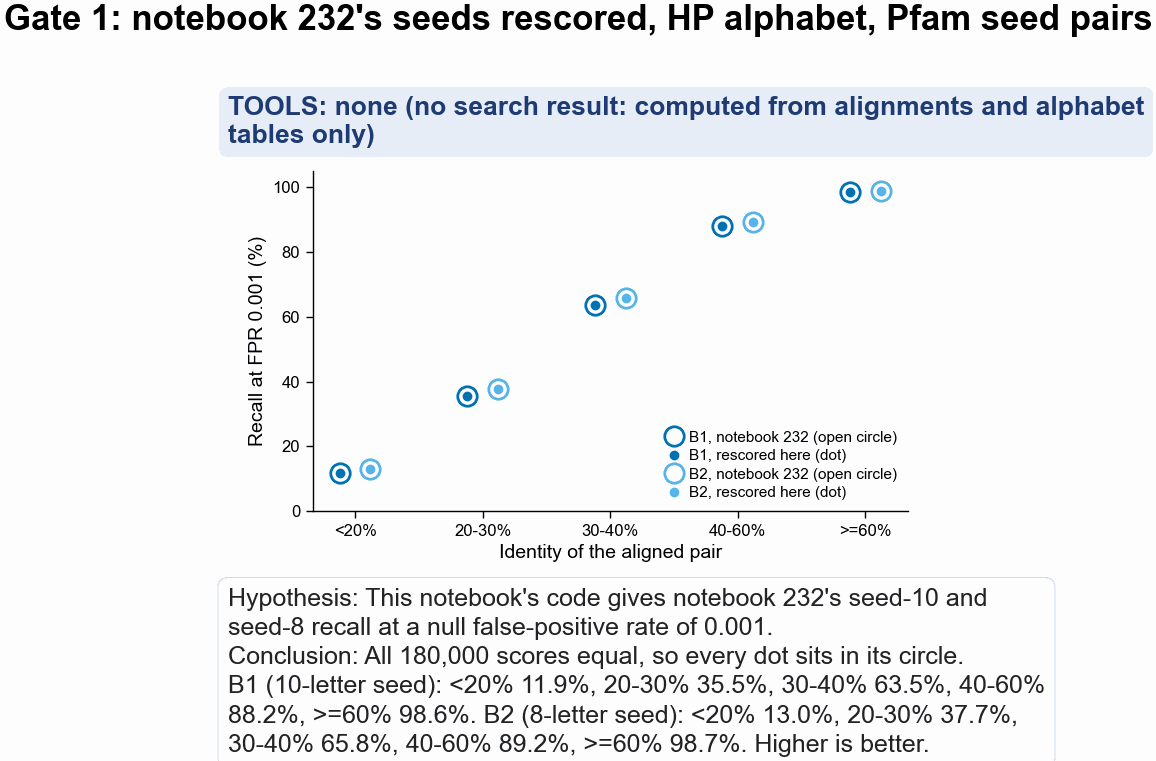

In [2]:
real_all, null_all, bin_all, pidx_all = lp.score_arrays(d, COLS)
thr_all, rate_all, rec_all = lp.threshold_and_recall(real_all, null_all, bin_all, FPR)

s232 = hc.add_identity_bin(
    pl.read_parquet(NB232).filter(
        (pl.col("dataset") == "pfam")
        & (pl.col("alphabet") == lp.ALPHABET)
        & (pl.col("penalty") == 2.0)
        & pl.col("seed").is_in([8, 10])
    )
)
r232 = se.recall_at_null_quantile(s232, ["seed"], FPR)
same_scores = d.join(
    s232.pivot(on="seed", index=["query", "target", "kind"], values="score"),
    on=["query", "target", "kind"],
).select(
    (pl.col("B1_ext") == pl.col("10")).mean().alias("B1 equal"),
    (pl.col("B2_ext") == pl.col("8")).mean().alias("B2 equal"),
    pl.len(),
)
print("share of the 180,000 comparisons whose score equals 232's stored score:")
print(same_scores)
gate1 = pl.DataFrame(
    {
        "identity_bin": BINS,
        "B1 here": rec_all[:, COLS.index("B1_ext")].round(3),
        "B1 in 232": [
            r232.filter((pl.col("seed") == 10) & (pl.col("identity_bin") == b))[
                "recall"
            ][0]
            for b in BINS
        ],
        "B2 here": rec_all[:, COLS.index("B2_ext")].round(3),
        "B2 in 232": [
            r232.filter((pl.col("seed") == 8) & (pl.col("identity_bin") == b))[
                "recall"
            ][0]
            for b in BINS
        ],
    }
).with_columns(pl.col("B1 in 232").round(3), pl.col("B2 in 232").round(3))
print(gate1)
print(
    f"thresholds: B1 {thr_all[0]:.0f}, B2 {thr_all[1]:.0f}; achieved null rate B1 {rate_all[0]:.5f}, B2 {rate_all[1]:.5f}"
)
gate1_ok = (gate1["B1 here"] == gate1["B1 in 232"]).all() and (
    gate1["B2 here"] == gate1["B2 in 232"]
).all()
print("Gate 1 reproduced to the digit:", gate1_ok)
assert gate1_ok

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55, layout=None)
x = np.arange(len(BINS))
for name, col232, colhere, dx in [
    ("B1", "B1 in 232", "B1 here", -0.12),
    ("B2", "B2 in 232", "B2 here", 0.12),
]:
    ax.plot(
        x + dx,
        100 * gate1[col232],
        color=COLOR[name],
        marker="o",
        ms=7,
        mfc="none",
        mew=1,
        lw=0,
        label=f"{name}, notebook 232 (open circle)",
    )
    ax.plot(
        x + dx,
        100 * gate1[colhere],
        color=COLOR[name],
        marker="o",
        ms=2.5,
        lw=0,
        label=f"{name}, rescored here (dot)",
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel("Recall at FPR 0.001 (%)")
ax.set_ylim(0, 105)
ax.legend(loc="lower right", fontsize=5.5)
hc.finish_figure(
    fig,
    FIG / "292_gate1_reproduce_nb232_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="This notebook's code gives notebook 232's seed-10 and seed-8 recall at a null false-positive rate of 0.001.",
    conclusion=(
        f"All 180,000 scores equal, so every dot sits in its circle. B1 (10-letter seed): "
        + ", ".join(f"{b} {100 * v:.1f}%" for b, v in zip(BINS, gate1["B1 here"]))
        + ". B2 (8-letter seed): "
        + ", ".join(f"{b} {100 * v:.1f}%" for b, v in zip(BINS, gate1["B2 here"]))
        + ". Higher is better."
    ),
    title="Gate 1: notebook 232's seeds rescored, HP alphabet, Pfam seed pairs",
    wrap=70,
)

## 2. The sweep, on the selection half

72 linked-pair settings (2 ways to pick keys × 4 anchor lengths × 3 window sizes × 3 gap
rules), each scored with extension. Recall at 20–30% identity at the 0.001 threshold, on a
random half of the true pairs and their own shuffled nulls. The setting with the highest
value is chosen here and only evaluated in section 4. Every square is one setting; the
chosen one is outlined. Settings whose threshold is 0 (the table's `threshold` column) never
reach an FPR of 0.001: almost no null comparison has a shared key, so any shared key counts.
Their FPR is lower than B1's and B2's, and their recall is not comparable.

selection half 30_000 pairs, report half 30_000 pairs


selection half, 20-30% bin: B1 0.384, B2 0.375
chosen: all_a6_g32_none; best one-partner-per-position setting: rand_a6_g32_none
shape: (72, 8)
┌──────────────────────┬──────┬────────┬─────────┬──────────┬───────────┬───────────┬──────────────┐
│ setting              ┆ mode ┆ anchor ┆ gap_max ┆ gap_rule ┆ threshold ┆ null_rate ┆ recall_20_30 │
│ ---                  ┆ ---  ┆ ---    ┆ ---     ┆ ---      ┆ ---       ┆ ---       ┆ ---          │
│ str                  ┆ str  ┆ i64    ┆ i64     ┆ str      ┆ f64       ┆ f64       ┆ f64          │
╞══════════════════════╪══════╪════════╪═════════╪══════════╪═══════════╪═══════════╪══════════════╡
│ all_a6_g32_none      ┆ all  ┆ 6      ┆ 32      ┆ none     ┆ 29.0      ┆ 0.00097   ┆ 0.464        │
│ all_a7_g32_none      ┆ all  ┆ 7      ┆ 32      ┆ none     ┆ 28.0      ┆ 0.00098   ┆ 0.46         │
│ all_a6_g16_none      ┆ all  ┆ 6      ┆ 16      ┆ none     ┆ 27.0      ┆ 0.00097   ┆ 0.446        │
│ all_a8_g32_none      ┆ all  ┆ 8      ┆ 32      

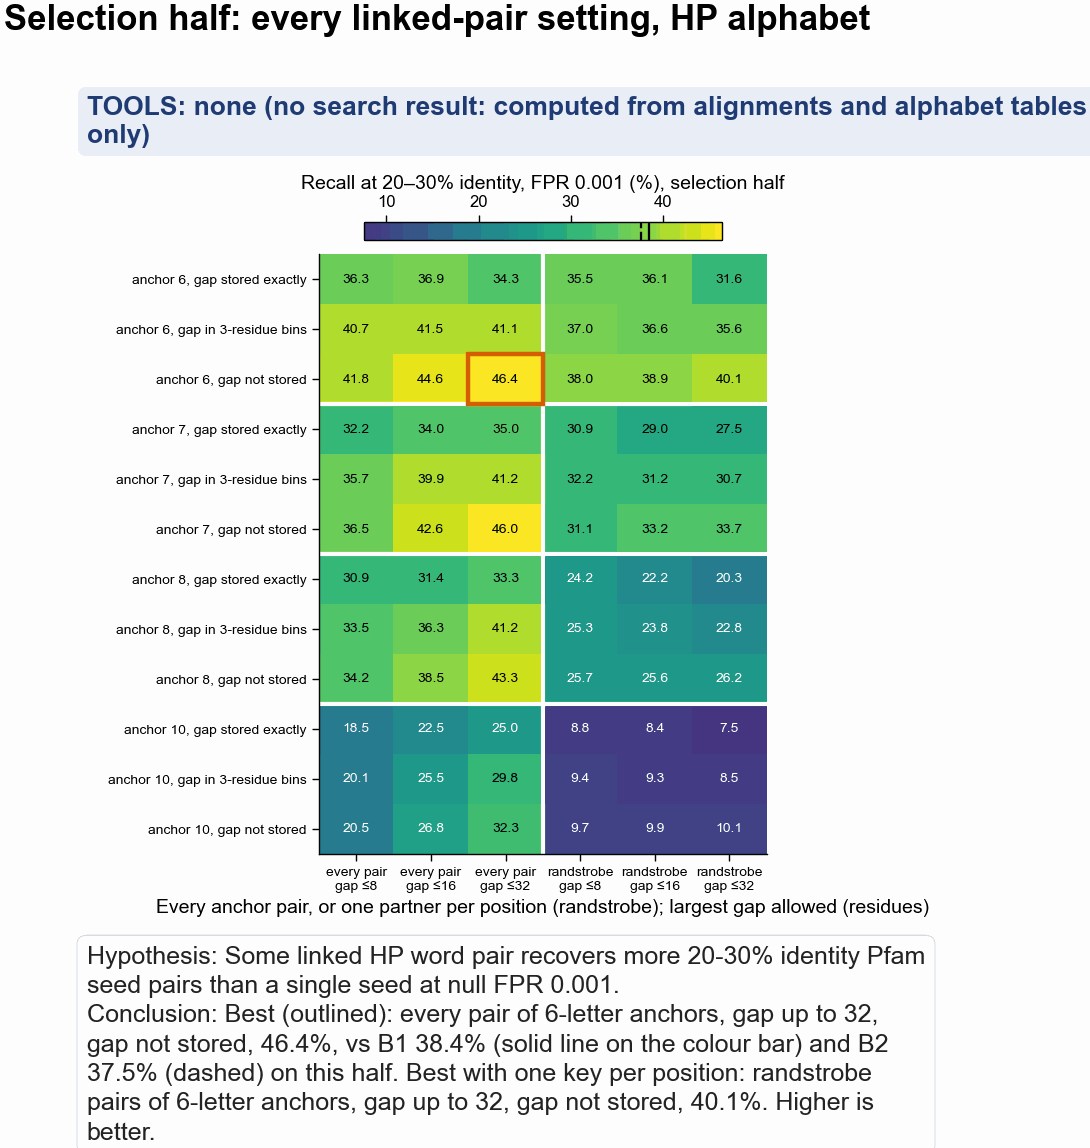

In [3]:
rng = np.random.default_rng(SPLIT_SEED)
perm = rng.permutation(np.unique(pidx_all))
select_ids = np.sort(perm[: perm.size // 2])
is_select = np.isin(pidx_all, select_ids)
print(
    f"selection half {is_select.sum():_} pairs, report half {(~is_select).sum():_} pairs"
)

real_s, null_s, bin_s = real_all[is_select], null_all[is_select], bin_all[is_select]
thr_s, rate_s, rec_s = lp.threshold_and_recall(real_s, null_s, bin_s, FPR)
b2030 = BINS.index("20-30%")
sweep = pl.DataFrame(
    {
        "setting": LINKED,
        "mode": [s[0] for s in lp.ALL_SETTINGS],
        "anchor": [s[1] for s in lp.ALL_SETTINGS],
        "gap_max": [s[2] for s in lp.ALL_SETTINGS],
        "gap_rule": [s[3] for s in lp.ALL_SETTINGS],
        "threshold": [thr_s[COLS.index(f"{s}_ext")] for s in LINKED],
        "null_rate": [rate_s[COLS.index(f"{s}_ext")] for s in LINKED],
        "recall_20_30": [rec_s[b2030, COLS.index(f"{s}_ext")] for s in LINKED],
    }
).sort("recall_20_30", descending=True)
CHOSEN = sweep["setting"][0]
CHOSEN_RAND = sweep.filter(pl.col("mode") == "rand")["setting"][0]
base_sel = {n: rec_s[b2030, COLS.index(f"{n}_ext")] for n in ["B1", "B2"]}
print(f"selection half, 20-30% bin: B1 {base_sel['B1']:.3f}, B2 {base_sel['B2']:.3f}")
print(f"chosen: {CHOSEN}; best one-partner-per-position setting: {CHOSEN_RAND}")
print(sweep.with_columns(pl.col("recall_20_30").round(3), pl.col("null_rate").round(5)))

# heatmap: rows = anchor length x gap rule, columns = key choice x window
rows_ = [(a, t) for a in lp.ANCHOR_LENGTHS for t in lp.TREATMENTS]
cols_ = [(m, g) for m in lp.MODES for g in lp.GAP_MAXES]
H = np.array(
    [
        [
            sweep.filter(pl.col("setting") == lp.setting_name(m, a, g, t))[
                "recall_20_30"
            ][0]
            for (m, g) in cols_
        ]
        for (a, t) in rows_
    ]
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 105, layout=None)
cmap = mpl.colors.ListedColormap(plt.cm.viridis(np.linspace(0.15, 1, 256)))
im = ax.imshow(
    H * 100, cmap=cmap, aspect="auto", vmin=H.min() * 100, vmax=H.max() * 100
)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = 100 * H[i, j]
        ax.text(
            j,
            i,
            f"{v:.1f}",
            ha="center",
            va="center",
            fontsize=5,
            color="white" if v < (H.min() + H.max()) * 50 else "black",
        )
for m, a, g, t in [s for s in lp.ALL_SETTINGS if lp.setting_name(*s) == CHOSEN]:
    ax.add_patch(
        Rectangle(
            (cols_.index((m, g)) - 0.5, rows_.index((a, t)) - 0.5),
            1,
            1,
            fill=False,
            ec=COLOR["linked"],
            lw=1.6,
            clip_on=False,
            zorder=10,
        )
    )
ax.set_xticks(
    range(len(cols_)),
    [f"{'every pair' if m == 'all' else 'randstrobe'}\ngap ≤{g}" for m, g in cols_],
    fontsize=5,
)
ax.set_xlabel(
    "Every anchor pair, or one partner per position (randstrobe); largest gap allowed (residues)"
)
ax.set_yticks(
    range(len(rows_)), [f"anchor {a}, {TREAT_LABEL[t]}" for a, t in rows_], fontsize=5
)
for k in range(1, len(lp.ANCHOR_LENGTHS)):
    ax.axhline(k * len(lp.TREATMENTS) - 0.5, color="white", lw=1.5)
ax.axvline(len(lp.GAP_MAXES) - 0.5, color="white", lw=1.5)
cb = fig.colorbar(im, ax=ax, location="top", shrink=0.8, pad=0.02)
cb.set_label("Recall at 20–30% identity, FPR 0.001 (%), selection half")
for n, ls_ in [("B1", "-"), ("B2", "--")]:
    cb.ax.axvline(100 * base_sel[n], color="black", lw=0.8, ls=ls_)
hc.finish_figure(
    fig,
    FIG / "292_sweep_recall_20_30_selection_half_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="Some linked HP word pair recovers more 20-30% identity Pfam seed pairs than a single seed at null FPR 0.001.",
    conclusion=(
        f"Best (outlined): {plain(CHOSEN)}, {100 * sweep['recall_20_30'][0]:.1f}%, vs B1 {100 * base_sel['B1']:.1f}% (solid line on the colour bar) and B2 {100 * base_sel['B2']:.1f}% (dashed) on this half. "
        f"Best with one key per position: {plain(CHOSEN_RAND)}, {100 * sweep.filter(pl.col('setting') == CHOSEN_RAND)['recall_20_30'][0]:.1f}%. Higher is better."
    ),
    title="Selection half: every linked-pair setting, HP alphabet",
    wrap=75,
    header_y=0.955,
)

## 3. What one key looks like on a real pair

One true pair from the report half at 20–30% identity, picked by a rule written before
looking: among pairs where the chosen setting scores above its threshold and B1 and B2 both
do not, keep those whose best key spans an insertion or deletion (query gap ≠ target gap),
then take the shortest alignment. Rows per block: query residues, query HP classes (H =
`ACFILMVWY`, P = `DEGHKNPQRST`), `|` where the two classes match, target HP classes, target
residues. The two boxes are the anchors of the best-scoring key; the line under them is
the gap; the black bar marks the longest run of matching HP classes, the longest exact HP
word the two share; the arrow marks the alignment column with an insertion.

The cell also lists which Pfam families the pairs found only by the linked key come from,
and how hydrophobic they are, because a key built from 6-letter HP words could favour
hydrophobic, membrane-spanning stretches.

report-half 20-30% pairs found by the chosen setting but by neither B1 nor B2: 709 of 7_512
634 of them have a best key across an insertion or deletion


hydrophobic share of the query (ACFILMVWY), report-half 20-30% pairs:
shape: (2, 4)
┌──────────────────────┬─────────┬────────┬────────────────────────────┐
│ found_only_by_linked ┆ n_pairs ┆ median ┆ share_with_60pct_or_more_H │
│ ---                  ┆ ---     ┆ ---    ┆ ---                        │
│ bool                 ┆ u32     ┆ f64    ┆ f64                        │
╞══════════════════════╪═════════╪════════╪════════════════════════════╡
│ false                ┆ 6803    ┆ 0.43   ┆ 0.031                      │
│ true                 ┆ 709     ┆ 0.432  ┆ 0.025                      │
└──────────────────────┴─────────┴────────┴────────────────────────────┘
Pfam families with the most pairs found only by the linked key:
shape: (10, 3)
┌─────────┬─────────────────┬─────┐
│ family  ┆ family_id       ┆ len │
│ ---     ┆ ---             ┆ --- │
│ str     ┆ str             ┆ u32 │
╞═════════╪═════════════════╪═════╡
│ PF00136 ┆ DNA_pol_B       ┆ 2   │
│ PF14158 ┆ YndJ            ┆ 2   │
│

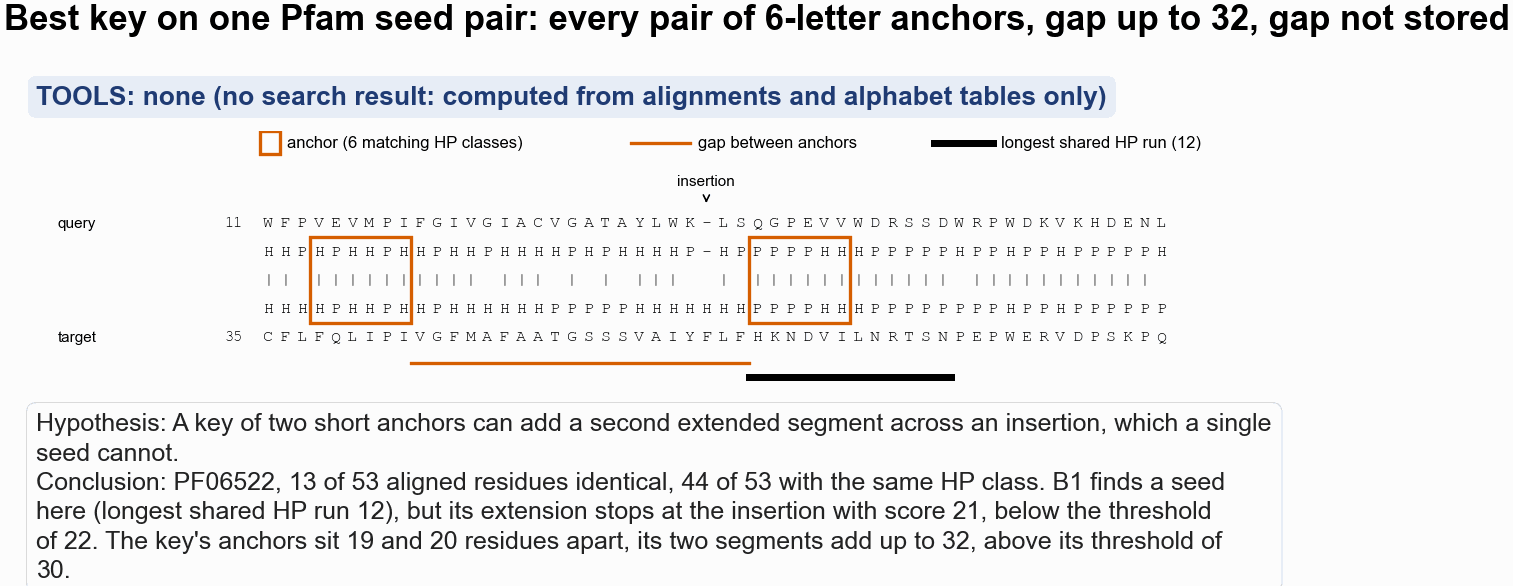

In [4]:
m_c, a_c, g_c, t_c = next(s for s in lp.ALL_SETTINGS if lp.setting_name(*s) == CHOSEN)
c_ext = COLS.index(f"{CHOSEN}_ext")
rep = ~is_select
thr_rep, _, _ = lp.threshold_and_recall(real_all[rep], null_all[rep], bin_all[rep], FPR)
cand = (
    rep
    & (bin_all == b2030)
    & (real_all[:, c_ext] > thr_rep[c_ext])
    & (real_all[:, COLS.index("B1_ext")] <= thr_rep[COLS.index("B1_ext")])
    & (real_all[:, COLS.index("B2_ext")] <= thr_rep[COLS.index("B2_ext")])
)
print(
    f"report-half 20-30% pairs found by the chosen setting but by neither B1 nor B2: {cand.sum():_} "
    f"of {(rep & (bin_all == b2030)).sum():_}"
)
aln = (
    pl.read_parquet(ALN)
    .filter(pl.col("lali") >= 50)
    .sample(n=60_000, seed=0, shuffle=True)
    .with_row_index("pair_index")
    .filter(pl.col("pair_index").is_in(pidx_all[cand].tolist()))
)
ex_rows = []
for r in aln.iter_rows(named=True):
    k = lp.best_key(r["qaln"], r["taln"], m_c, a_c, g_c, t_c)
    if k and k["gap_query"] != k["gap_target"]:
        ex_rows.append({**r, **k})
ex = (
    pl.DataFrame(ex_rows)
    .with_columns(pl.col("qaln").str.len_chars().alias("aln_len"))
    .sort("aln_len", "pair_index")
)
print(f"{ex.height} of them have a best key across an insertion or deletion")
all_2030 = (
    pl.read_parquet(ALN)
    .filter(pl.col("lali") >= 50)
    .sample(n=60_000, seed=0, shuffle=True)
    .with_row_index("pair_index")
    .filter(pl.col("pair_index").is_in(pidx_all[rep & (bin_all == b2030)].tolist()))
)
H_SET = set("ACFILMVWY")


def h_share(aln_str):
    res = [c for c in aln_str.upper() if c != "-"]
    return sum(c in H_SET for c in res) / len(res)


all_2030 = all_2030.with_columns(
    pl.col("qaln")
    .map_elements(h_share, return_dtype=pl.Float64)
    .alias("query_h_share"),
    pl.col("pair_index").is_in(pidx_all[cand].tolist()).alias("found_only_by_linked"),
)
print("hydrophobic share of the query (ACFILMVWY), report-half 20-30% pairs:")
print(
    all_2030.group_by("found_only_by_linked")
    .agg(
        pl.len().alias("n_pairs"),
        pl.col("query_h_share").median().round(3).alias("median"),
        (pl.col("query_h_share") >= 0.6)
        .mean()
        .round(3)
        .alias("share_with_60pct_or_more_H"),
    )
    .sort("found_only_by_linked")
)
print("Pfam families with the most pairs found only by the linked key:")
print(
    all_2030.filter(pl.col("found_only_by_linked"))
    .group_by("family", "family_id")
    .len()
    .sort("len", descending=True)
    .head(10)
)
E = ex.row(0, named=True)
row_scores = real_all[np.flatnonzero(pidx_all == E["pair_index"])[0]]
assert E["score"] == row_scores[c_ext], "best_key disagrees with the stored score"

tab = lp.TABLES[lp.ALPHABET]
q, t = E["qaln"], E["taln"]
qc, tc = (
    tab[np.frombuffer(q.encode(), np.uint8)],
    tab[np.frombuffer(t.encode(), np.uint8)],
)
match = (qc == tc) & (qc != lp.GAP) & (tc != lp.GAP)
run = np.diff(np.concatenate(([0], match.astype(int), [0])))
starts, ends = np.flatnonzero(run == 1), np.flatnonzero(run == -1)
lr = int(np.argmax(ends - starts))
run_s, run_e = starts[lr], ends[lr]
aligned = (np.frombuffer(q.encode(), np.uint8) != ord("-")) & (
    np.frombuffer(t.encode(), np.uint8) != ord("-")
)
n_ident = sum(1 for x, y in zip(q, t) if x == y and x != "-")
hp = lambda c: "".join(
    "-" if ch == "-" else ("H" if v == 0 else ("P" if v == 1 else "X"))
    for ch, v in zip(c, tab[np.frombuffer(c.encode(), np.uint8)])
)
q_hp, t_hp = hp(q), hp(t)
mline = "".join("|" if mm else " " for mm in match)
q0 = int(E["query"].split("/")[1].split("-")[0])
t0 = int(E["target"].split("/")[1].split("-")[0])
print(
    f"{E['family']}: {E['query']} vs {E['target']}; {n_ident} of {int(aligned.sum())} aligned columns identical "
    f"({100 * E['seqid_ali']:.0f}%), {int(match.sum())} of {int(aligned.sum())} with matching HP classes"
)
print(
    f"best key: anchors of {a_c} at alignment columns {E['c1']} and {E['c2']}; gap {E['gap_query']} residues in the query, "
    f"{E['gap_target']} in the target; key score {E['score']:.0f} (threshold {thr_rep[c_ext]:.0f}); {E['n_keys']} shared keys"
)
print(
    f"B1 score {row_scores[COLS.index('B1_ext')]:.0f}, B2 score {row_scores[COLS.index('B2_ext')]:.0f} (threshold {thr_rep[COLS.index('B1_ext')]:.0f}); "
    f"longest shared HP run {run_e - run_s} residues"
)

W = 70
nblk = int(np.ceil(len(q) / W))
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 16 + 22 * nblk, layout=None)
ax.set_axis_off()
ax.set_xlim(-12, W + 1)
ax.set_ylim(-nblk * 7.2 + 1.4, 3.2)
mono = dict(family="monospace", fontsize=6, va="center")


def resnum(s, start, upto):
    return start + sum(1 for ch in s[:upto] if ch != "-")


ax.add_patch(Rectangle((0, 2.4), 1.2, 0.8, fill=False, ec=COLOR["linked"], lw=1.2))
ax.text(1.6, 2.8, f"anchor ({a_c} matching HP classes)", fontsize=6, va="center")
ax.plot([22, 25.5], [2.8, 2.8], color=COLOR["linked"], lw=1.2)
ax.text(26, 2.8, "gap between anchors", fontsize=6, va="center")
ax.plot([40, 43.5], [2.8, 2.8], color="black", lw=2.5)
ax.text(44, 2.8, f"longest shared HP run ({run_e - run_s})", fontsize=6, va="center")
for b in range(nblk):
    s, e = b * W, min((b + 1) * W, len(q))
    y0 = -b * 7.2
    for k_, (lab, txt) in enumerate(
        [
            (f"{resnum(q, q0, s)}", q[s:e]),
            ("", q_hp[s:e]),
            ("", mline[s:e]),
            ("", t_hp[s:e]),
            (f"{resnum(t, t0, s)}", t[s:e]),
        ]
    ):
        y = y0 - k_
        ax.text(-1, y, lab, ha="right", **{**mono, "fontsize": 5.5})
        for i, ch in enumerate(txt):
            ax.text(i + 0.5, y, ch, ha="center", **mono)
    ax.text(-12, y0, "query", fontsize=5.5, va="center")
    ax.text(-12, y0 - 4, "target", fontsize=5.5, va="center")
    for cstart in (E["c1"], E["c2"]):
        lo, hi = max(cstart, s), min(cstart + a_c, e)
        if lo < hi:
            ax.add_patch(
                Rectangle(
                    (lo - s, y0 - 3.5),
                    hi - lo,
                    3.0,
                    fill=False,
                    ec=COLOR["linked"],
                    lw=1.2,
                )
            )
    lo, hi = max(E["c1"] + a_c, s), min(E["c2"], e)
    if lo < hi:
        ax.plot([lo - s, hi - s], [y0 - 4.9, y0 - 4.9], color=COLOR["linked"], lw=1.2)
    lo, hi = max(run_s, s), min(run_e, e)
    if lo < hi:
        ax.plot([lo - s, hi - s], [y0 - 5.4, y0 - 5.4], color="black", lw=2.5)
    for col_ in range(max(E["c1"] + a_c, s), min(E["c2"], e)):
        if q[col_] == "-" or t[col_] == "-":
            ax.annotate(
                "insertion",
                xy=(col_ - s + 0.5, y0 + 0.5),
                xytext=(col_ - s + 0.5, y0 + 1.3),
                ha="center",
                fontsize=5.5,
                arrowprops=dict(arrowstyle="->", lw=0.6, color="black"),
            )
hc.finish_figure(
    fig,
    FIG / "292_example_linked_key_pfam_seed_pair.png",
    tools=hc.NO_TOOL,
    hypothesis="A key of two short anchors can add a second extended segment across an insertion, which a single seed cannot.",
    conclusion=(
        f"{E['family']}, {n_ident} of {int(aligned.sum())} aligned residues identical, {int(match.sum())} of {int(aligned.sum())} with the same HP class. "
        f"B1 finds a seed here (longest shared HP run {run_e - run_s}), but its extension stops at the insertion with score {row_scores[COLS.index('B1_ext')]:.0f}, below the threshold of {thr_rep[COLS.index('B1_ext')]:.0f}. "
        f"The key's anchors sit {E['gap_query']} and {E['gap_target']} residues apart, its two segments add up to {E['score']:.0f}, above its threshold of {thr_rep[c_ext]:.0f}."
    ),
    title=f"Best key on one Pfam seed pair: {plain(CHOSEN)}",
    wrap=110,
)

## 4. The verdict, on the report half

Recall at the 0.001 threshold per identity bin on the half not used for choosing, for B1,
B2 and the chosen setting with and without extension. Bars are bootstrap 95% intervals
(1,000 resamples of pairs; each true pair is resampled with its own shuffled targets and
the threshold is recomputed each time). The verdict line under the figure is computed from
the same numbers.

shape: (25, 9)
┌──────────────┬───────────────────────┬───────────┬───────────┬──────────────┬──────────────┬────────┬────────┬─────────┐
│ score        ┆ column                ┆ threshold ┆ null_rate ┆ identity_bin ┆ n_true_pairs ┆ recall ┆ ci_low ┆ ci_high │
│ ---          ┆ ---                   ┆ ---       ┆ ---       ┆ ---          ┆ ---          ┆ ---    ┆ ---    ┆ ---     │
│ str          ┆ str                   ┆ f64       ┆ f64       ┆ str          ┆ i64          ┆ f64    ┆ f64    ┆ f64     │
╞══════════════╪═══════════════════════╪═══════════╪═══════════╪══════════════╪══════════════╪════════╪════════╪═════════╡
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ <20%         ┆ 3256         ┆ 0.116  ┆ 0.096  ┆ 0.141   │
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ 20-30%       ┆ 7512         ┆ 0.356  ┆ 0.323  ┆ 0.397   │
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ 30-40%       ┆ 7024         ┆ 0.633  ┆ 0.6    ┆ 0.669   │
│

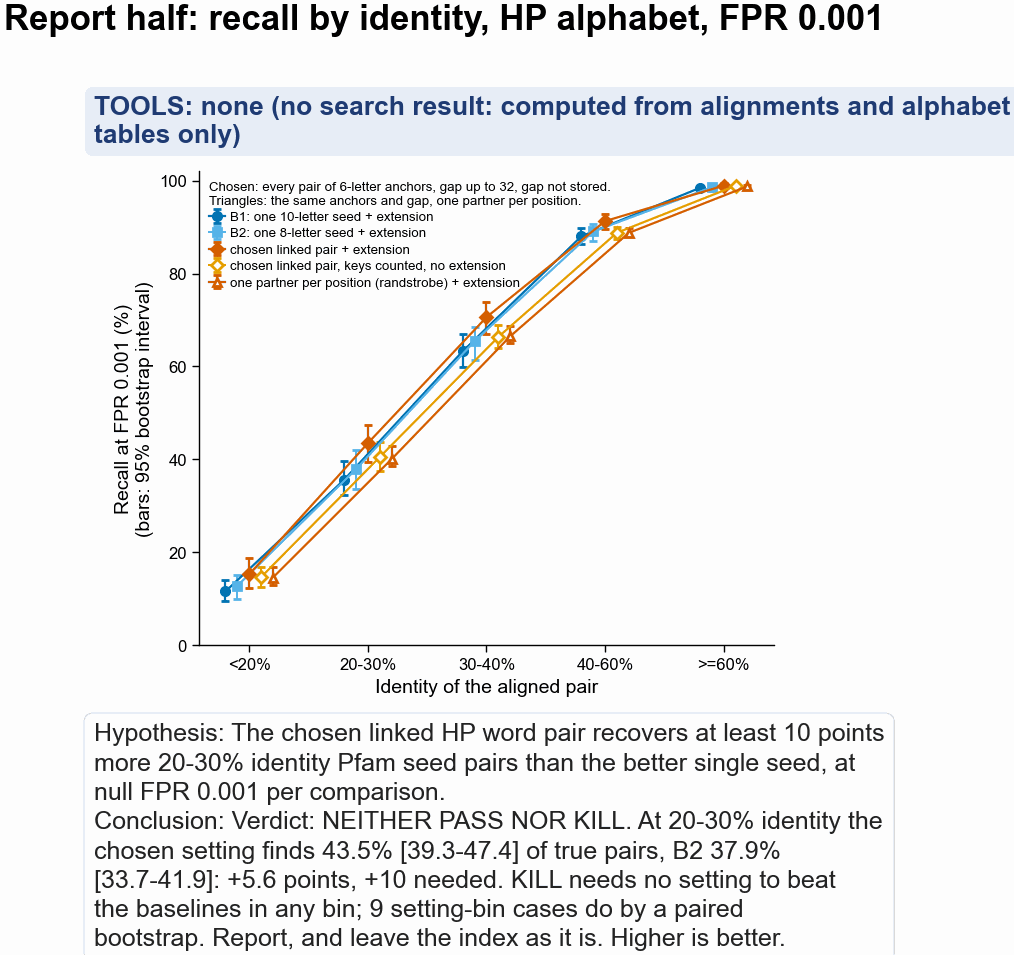

In [5]:
real_r, null_r, bin_r = real_all[rep], null_all[rep], bin_all[rep]
# every linked setting is bootstrapped too: the KILL rule is about any setting, in any bin
EXT = ["B1_ext", "B2_ext"] + [f"{x}_ext" for x in LINKED] + [f"{CHOSEN}_count"]
idx = [COLS.index(c) for c in EXT]
thr_r, rate_r, rec_r = lp.threshold_and_recall(
    real_r[:, idx], null_r[:, :, idx], bin_r, FPR
)
boot = lp.bootstrap_recall(
    real_r[:, idx], null_r[:, :, idx], bin_r, FPR, N_BOOT, seed=1
)
lo, hi = np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
SHOW = {
    "B1": "B1_ext",
    "B2": "B2_ext",
    "linked": f"{CHOSEN}_ext",
    "linked_count": f"{CHOSEN}_count",
    "randstrobe": f"{CHOSEN_RAND}_ext",
}
J = {n: EXT.index(c) for n, c in SHOW.items()}
res = pl.DataFrame(
    [
        {
            "score": n,
            "column": SHOW[n],
            "threshold": thr_r[j],
            "null_rate": rate_r[j],
            "identity_bin": b,
            "n_true_pairs": int((bin_r == i).sum()),
            "recall": rec_r[i, j],
            "ci_low": lo[i, j],
            "ci_high": hi[i, j],
        }
        for n, j in J.items()
        for i, b in enumerate(BINS)
    ]
)
print(
    res.with_columns(
        pl.col("recall", "ci_low", "ci_high").round(3), pl.col("null_rate").round(5)
    )
)

jB1, jB2, jL = J["B1"], J["B2"], J["linked"]
best_base = jB1 if rec_r[b2030, jB1] >= rec_r[b2030, jB2] else jB2
base_name = "B1" if best_base == jB1 else "B2"
gain = rec_r[b2030, jL] - rec_r[b2030, best_base]
pass_rule = gain >= 0.10 and lo[b2030, jL] > hi[b2030, best_base]
base_hi = np.maximum(
    hi[:, jB1], hi[:, jB2]
)  # upper end of the better baseline's interval, per bin
lin = [EXT.index(f"{x}_ext") for x in LINKED]
# reading 1 (the one PASS uses): the setting's interval lies wholly above the baselines' intervals
beats_strict = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if lo[i, j] > base_hi[i]
]
# reading 2: the setting's own value lies above the baselines' intervals
beats_loose = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if rec_r[i, j] > base_hi[i]
]
# reading 3: a paired bootstrap of the setting minus the better baseline (same resamples) excludes 0
better = [jB1 if rec_r[i, jB1] >= rec_r[i, jB2] else jB2 for i in range(len(BINS))]
beats_paired = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if np.percentile(boot[:, i, j] - boot[:, i, better[i]], 2.5) > 0
]
print(
    "All 72 linked settings, report half, against the better of B1 and B2 in each identity bin:"
)
print(
    f"  setting-bin cases whose interval lies wholly above both baselines' intervals: {len(beats_strict)}"
)
print(
    f"  setting-bin cases whose value lies above both baselines' intervals: {len(beats_loose)}"
)
print(
    f"  setting-bin cases whose paired gain over the better baseline excludes 0: {len(beats_paired)}"
)
cases = (
    pl.DataFrame(beats_loose, schema=["setting", "identity_bin"], orient="row")
    .with_columns(pl.lit("value above both intervals").alias("reading"))
    .vstack(
        pl.DataFrame(
            beats_paired, schema=["setting", "identity_bin"], orient="row"
        ).with_columns(pl.lit("paired gain excludes 0").alias("reading"))
    )
)
print(cases.sort("reading", "setting", "identity_bin"))
if pass_rule:
    VERDICT = "PASS"
elif not (beats_strict or beats_loose or beats_paired):
    VERDICT = "KILL"
else:
    VERDICT = "NEITHER PASS NOR KILL"
diff_boot = boot[:, b2030, jL] - boot[:, b2030, best_base]
d_lo, d_hi = np.percentile(diff_boot, [2.5, 97.5])
verdict_line = (
    f"Verdict: {VERDICT}. At 20-30% identity the chosen setting finds {100 * rec_r[b2030, jL]:.1f}% "
    f"[{100 * lo[b2030, jL]:.1f}-{100 * hi[b2030, jL]:.1f}] of true pairs, {base_name} {100 * rec_r[b2030, best_base]:.1f}% "
    f"[{100 * lo[b2030, best_base]:.1f}-{100 * hi[b2030, best_base]:.1f}]: +{100 * gain:.1f} points, +10 needed. "
    f"KILL needs no setting to beat the baselines in any bin; {len(beats_paired)} setting-bin cases do by a paired bootstrap. Report, and leave the index as it is."
)
print(verdict_line)
print(
    f"Only the strictest reading (one interval wholly above another) would call it KILL; the other two do not. Not PASS under any reading."
)
print(
    f"Gain of the chosen setting over {base_name} at 20-30%, paired bootstrap (same resamples): {100 * gain:.1f} points, 95% interval {100 * d_lo:.1f} to {100 * d_hi:.1f}"
)
names = list(J)
jR = J["randstrobe"]
r_lo, r_hi = np.percentile(boot[:, b2030, jR] - boot[:, b2030, best_base], [2.5, 97.5])
print(
    f"Randstrobe setting over {base_name} at 20-30%, paired: {100 * (rec_r[b2030, jR] - rec_r[b2030, best_base]):.1f} points, 95% interval {100 * r_lo:.1f} to {100 * r_hi:.1f}"
)
# why the single-setting intervals are wide: recall at 20-30% one score step either side of the threshold
for n in ["B2", "linked"]:
    j = J[n]
    col = real_r[:, idx[j]][bin_r == b2030]
    nul = null_r[:, :, idx[j]].ravel()
    print(
        f"{n}: "
        + "; ".join(
            f"threshold {t:.0f}: recall {100 * (col > t).mean():.1f}%, null rate {(nul > t).mean():.5f}"
            for t in (thr_r[j] - 1, thr_r[j], thr_r[j] + 1)
        )
    )

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 72, layout=None)
x = np.arange(len(BINS))
style = {
    "B1": ("B1: one 10-letter seed + extension", "o", True, "B1"),
    "B2": ("B2: one 8-letter seed + extension", "s", True, "B2"),
    "linked": ("chosen linked pair + extension", "D", True, "linked"),
    "linked_count": (
        "chosen linked pair, keys counted, no extension",
        "D",
        False,
        "linked_count",
    ),
    "randstrobe": (
        "one partner per position (randstrobe) + extension",
        "^",
        False,
        "linked",
    ),
}
off = {"B1": -0.2, "B2": -0.1, "linked": 0.0, "linked_count": 0.1, "randstrobe": 0.2}
for n, (lab, mk, filled, ckey) in style.items():
    j = J[n]
    ax.errorbar(
        x + off[n],
        100 * rec_r[:, j],
        yerr=[100 * (rec_r[:, j] - lo[:, j]), 100 * (hi[:, j] - rec_r[:, j])],
        color=COLOR[ckey],
        marker=mk,
        ms=3,
        mfc=COLOR[ckey] if filled else "white",
        lw=0.8,
        capsize=1.5,
        label=lab,
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel("Recall at FPR 0.001 (%)\n(bars: 95% bootstrap interval)")
ax.set_ylim(0, 102)
ax.legend(
    loc="upper left",
    fontsize=4.8,
    title=f"Chosen: {plain(CHOSEN)}.\nTriangles: the same anchors and gap, one partner per position.",
    title_fontsize=4.8,
    alignment="left",
)
hc.finish_figure(
    fig,
    FIG / "292_recall_by_identity_report_half_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="The chosen linked HP word pair recovers at least 10 points more 20-30% identity Pfam seed pairs than the better single seed, at null FPR 0.001 per comparison.",
    conclusion=verdict_line + " Higher is better.",
    title="Report half: recall by identity, HP alphabet, FPR 0.001",
    wrap=70,
)

## 5. Bits, measured on Swiss-Prot

How often does a key match by chance? For each setting, every key in Swiss-Prot
(`uniprot_sprot.fasta.gz`, 572,970 proteins, encoded in `hp_thomas_dill2`) is counted, and
the chance that two keys drawn at random are equal is the sum over keys of p(key)². Its
−log2 is the measured number of bits. The prediction drawn as a line assumes one bit per HP
letter, plus log2 of the number of gap values the key stores. The y-axis is the expected
number of chance key matches between two unrelated sequences of 131 residues (the median
domain length of the pairs above), over every pair of positions, not one diagonal.

Key frequencies are counted directly from Swiss-Prot. The project's stored Swiss-Prot
spectra (`~/data/kmerseek-kmer-spectra/sprot.hp_thomas_dill.k*.spectrum.csv.gz`) start at
15 letters and list 72,533 distinct HP 15-mers, more than the 32,768 two letters allow, so
they use a different encoding. Only keys that fit inside 131 residues are counted.

valid HP 15-mers counted in Swiss-Prot: 199_555_063; median pair length 131
single words:
shape: (4, 4)
┌────────┬────────────────┬───────────────┬─────────────────────────┐
│ anchor ┆ predicted_bits ┆ measured_bits ┆ expected_chance_matches │
│ ---    ┆ ---            ┆ ---           ┆ ---                     │
│ i64    ┆ f64            ┆ f64           ┆ f64                     │
╞════════╪════════════════╪═══════════════╪═════════════════════════╡
│ 6      ┆ 6.0            ┆ 5.79          ┆ 278.84                  │
│ 7      ┆ 7.0            ┆ 6.75          ┆ 140.02                  │
│ 8      ┆ 8.0            ┆ 7.71          ┆ 70.43                   │
│ 10     ┆ 10.0           ┆ 9.62          ┆ 17.94                   │
└────────┴────────────────┴───────────────┴─────────────────────────┘
shape: (72, 9)
┌──────┬────────┬─────────┬───────────┬───────────────────┬────────────────┬───────────────┬──────────────────────────┬─────────────────────────┐
│ mode ┆ anchor ┆ gap_max ┆ treatme

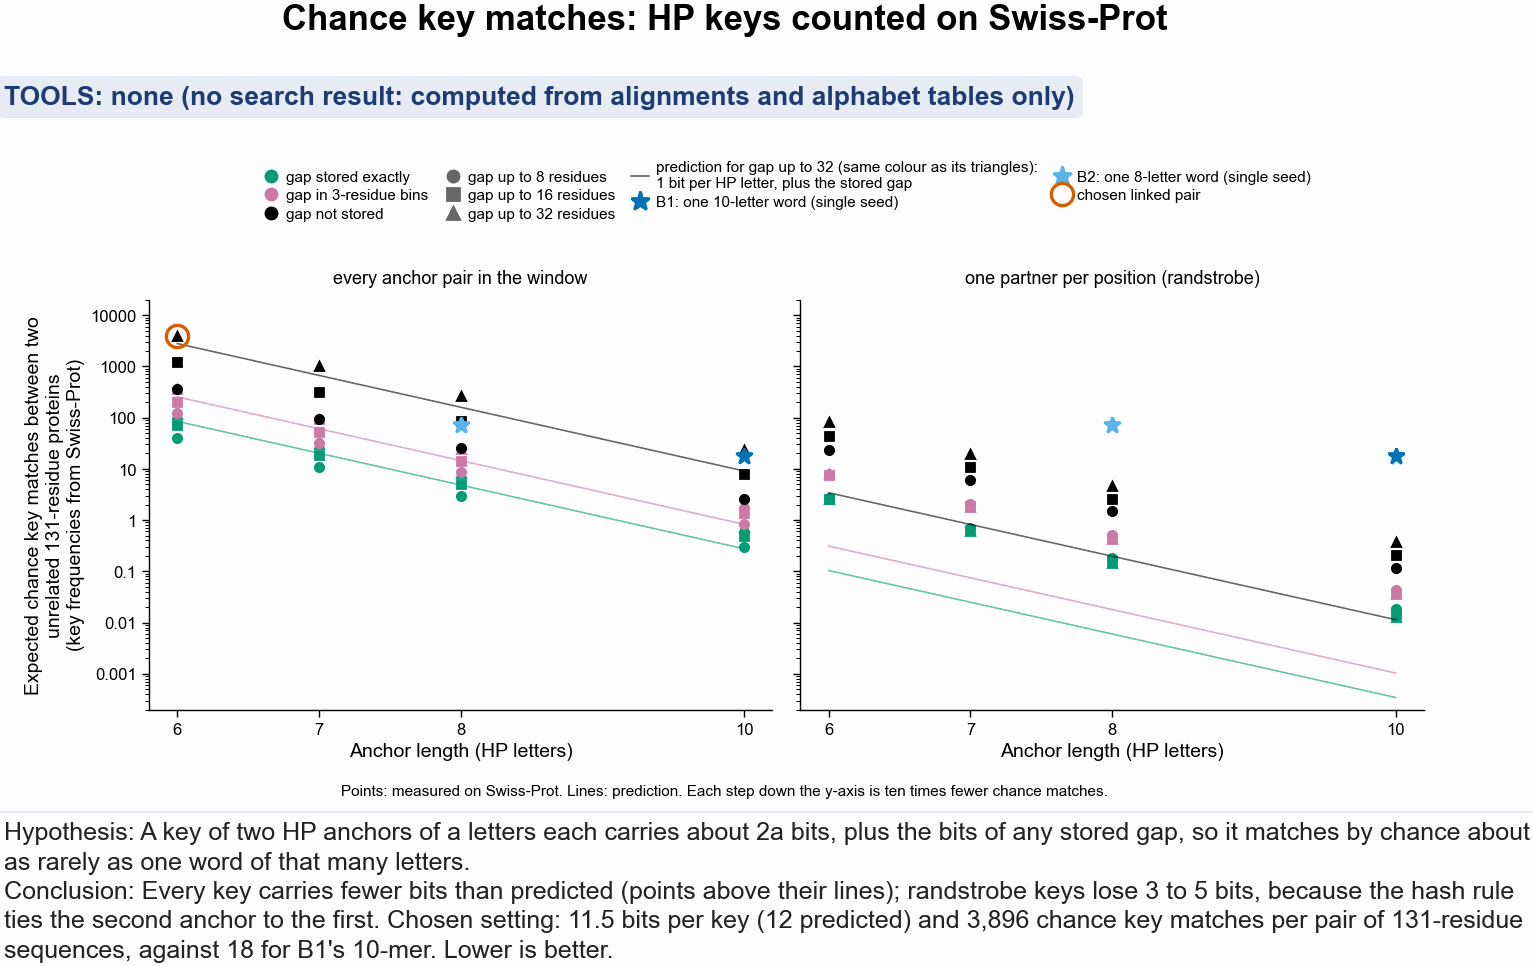

In [6]:
spec = pl.read_parquet(SPECTRUM)
check = spec.filter(pl.col("mode") == "check")
spec = spec.filter(pl.col("mode") != "check").with_columns(
    (pl.col("keys_per_sequence") ** 2 * (2.0 ** -pl.col("predicted_bits"))).alias(
        "predicted_chance_matches"
    ),
    (pl.col("predicted_bits") - pl.col("measured_bits")).alias(
        "bits_short_of_prediction"
    ),
)
L_MED = spec["median_length"][0]
print(
    f"valid HP 15-mers counted in Swiss-Prot: {int(check['rate'][0]):_}; median pair length {L_MED:.0f}"
)
words = spec.filter(pl.col("mode") == "word").select(
    "anchor", "predicted_bits", "measured_bits", "expected_chance_matches"
)
print("single words:")
print(words.with_columns(pl.col("measured_bits", "expected_chance_matches").round(2)))
tabl = (
    spec.filter(pl.col("mode") != "word")
    .select(
        "mode",
        "anchor",
        "gap_max",
        "treatment",
        "keys_per_sequence",
        "predicted_bits",
        "measured_bits",
        "bits_short_of_prediction",
        "expected_chance_matches",
    )
    .sort("mode", "gap_max", "treatment", "anchor")
)
print(
    tabl.with_columns(
        pl.col(
            "keys_per_sequence",
            "predicted_bits",
            "measured_bits",
            "bits_short_of_prediction",
        ).round(2),
        pl.col("expected_chance_matches").round(3),
    )
)
ch = spec.filter(
    (pl.col("mode") == m_c)
    & (pl.col("anchor") == a_c)
    & (pl.col("gap_max") == g_c)
    & (pl.col("treatment") == t_c)
).row(0, named=True)
w10 = words.filter(pl.col("anchor") == 10).row(0, named=True)
w8 = words.filter(pl.col("anchor") == 8).row(0, named=True)
print(
    f"chosen {CHOSEN}: {ch['measured_bits']:.1f} bits per key measured (prediction {ch['predicted_bits']:.1f}); "
    f"{ch['expected_chance_matches']:.1f} chance key matches per comparison of two {L_MED:.0f}-residue sequences; "
    f"B1's 10-mer {w10['measured_bits']:.1f} bits, {w10['expected_chance_matches']:.1f}; B2's 8-mer {w8['measured_bits']:.1f} bits, {w8['expected_chance_matches']:.1f}"
)

fig, axd = plt.subplot_mosaic(
    [["legend", "legend"], ["all", "rand"]],
    figsize=(pf.TWO_COLUMN_MM * pf.MM, 85 * pf.MM),
    height_ratios=[0.28, 1],
    sharey=False,
)
from matplotlib.lines import Line2D

handles = (
    [
        Line2D([], [], color=COLOR[tr], marker="o", lw=0, ms=4, label=TREAT_LABEL[tr])
        for tr in lp.TREATMENTS
    ]
    + [
        Line2D(
            [], [], color="0.4", marker=mk, lw=0, ms=4, label=f"gap up to {g} residues"
        )
        for g, mk in zip(lp.GAP_MAXES, ["o", "s", "^"])
    ]
    + [
        Line2D(
            [],
            [],
            color="0.4",
            lw=0.6,
            label="prediction for gap up to 32 (same colour as its triangles):\n1 bit per HP letter, plus the stored gap",
        )
    ]
    + [
        Line2D(
            [],
            [],
            color=COLOR[n],
            marker="*",
            ms=7,
            lw=0,
            label=f"{n}: one {a_}-letter word (single seed)",
        )
        for n, a_ in [("B1", 10), ("B2", 8)]
    ]
    + [
        Line2D(
            [],
            [],
            marker="o",
            ms=8,
            mfc="none",
            mec=COLOR["linked"],
            mew=1.2,
            lw=0,
            label="chosen linked pair",
        )
    ]
)
axd["legend"].set_axis_off()
axd["legend"].legend(handles=handles, loc="center", ncol=4, fontsize=5.5, frameon=False)
for mode in lp.MODES:
    ax = axd[mode]
    for tr in lp.TREATMENTS:
        for g, mk in zip(lp.GAP_MAXES, ["o", "s", "^"]):
            s_ = spec.filter(
                (pl.col("mode") == mode)
                & (pl.col("treatment") == tr)
                & (pl.col("gap_max") == g)
            ).sort("anchor")
            if g == max(lp.GAP_MAXES):
                ax.plot(
                    s_["anchor"],
                    s_["predicted_chance_matches"],
                    color=COLOR[tr],
                    lw=0.6,
                    alpha=0.6,
                )
            ax.plot(
                s_["anchor"],
                s_["expected_chance_matches"],
                color=COLOR[tr],
                marker=mk,
                ms=3,
                lw=0,
            )
    for name, a_ in [("B1", 10), ("B2", 8)]:
        r_ = words.filter(pl.col("anchor") == a_)
        ax.plot(
            r_["anchor"],
            r_["expected_chance_matches"],
            marker="*",
            ms=6,
            lw=0,
            color=COLOR[name],
        )
    if mode == m_c:
        ax.plot(
            [a_c],
            [ch["expected_chance_matches"]],
            marker="o",
            ms=8,
            mfc="none",
            mec=COLOR["linked"],
            mew=1.2,
            lw=0,
        )
    ax.set_yscale("log")
    ax.set_ylim(2e-4, 2e4)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xticks(lp.ANCHOR_LENGTHS)
    ax.set_xlabel("Anchor length (HP letters)")
    ax.set_title(MODE_LABEL[mode], fontsize=6.5)
axd["all"].set_ylabel(
    "Expected chance key matches between two\nunrelated 131-residue proteins\n(key frequencies from Swiss-Prot)"
)
axd["rand"].set_yticklabels([])
fig.text(
    0.5,
    -0.02,
    "Points: measured on Swiss-Prot. Lines: prediction. Each step down the y-axis is ten times fewer chance matches.",
    ha="center",
    fontsize=5.5,
)
hc.finish_figure(
    fig,
    FIG / "292_chance_key_matches_swissprot.png",
    tools=hc.NO_TOOL,
    title="Chance key matches: HP keys counted on Swiss-Prot",
    hypothesis="A key of two HP anchors of a letters each carries about 2a bits, plus the bits of any stored gap, so it matches by chance about as rarely as one word of that many letters.",
    conclusion=(
        f"Every key carries fewer bits than predicted (points above their lines); randstrobe keys lose 3 to 5 bits, because the hash rule ties the second anchor to the first. "
        f"Chosen setting: {ch['measured_bits']:.1f} bits per key ({ch['predicted_bits']:.0f} predicted) and {ch['expected_chance_matches']:,.0f} chance key matches per pair of {L_MED:.0f}-residue sequences, "
        f"against {w10['expected_chance_matches']:.0f} for B1's 10-mer. Lower is better."
    ),
    footer_y=-0.06,
    wrap=140,
)

## 6. Summary and what this does not show

In [7]:
print(verdict_line)
print()
print("Report half, recall at null FPR 0.001 (95% bootstrap interval):")
for n in ["B1", "B2", "linked", "linked_count", "randstrobe"]:
    j = J[n]
    print(
        f"  {n:13s} {SHOW[n]:28s} "
        + "  ".join(
            f"{b} {100 * rec_r[i, j]:.1f} [{100 * lo[i, j]:.1f}-{100 * hi[i, j]:.1f}]"
            for i, b in enumerate(BINS)
        )
    )
print()
print(
    f"False pairs per query at 0.001 per comparison against Swiss-Prot: {FPR * SWISSPROT_PROTEINS:.0f}"
)

Verdict: NEITHER PASS NOR KILL. At 20-30% identity the chosen setting finds 43.5% [39.3-47.4] of true pairs, B2 37.9% [33.7-41.9]: +5.6 points, +10 needed. KILL needs no setting to beat the baselines in any bin; 9 setting-bin cases do by a paired bootstrap. Report, and leave the index as it is.

Report half, recall at null FPR 0.001 (95% bootstrap interval):
  B1            B1_ext                       <20% 11.6 [9.6-14.1]  20-30% 35.6 [32.3-39.7]  30-40% 63.3 [60.0-66.9]  40-60% 88.0 [86.4-89.8]  >=60% 98.4 [97.9-98.9]
  B2            B2_ext                       <20% 12.8 [10.0-15.0]  20-30% 37.9 [33.7-41.9]  30-40% 65.4 [61.4-68.6]  40-60% 89.1 [87.1-90.6]  >=60% 98.6 [97.9-99.0]
  linked        all_a6_g32_none_ext          <20% 15.3 [12.3-18.8]  20-30% 43.5 [39.3-47.4]  30-40% 70.6 [67.0-73.9]  40-60% 91.3 [89.5-92.8]  >=60% 98.9 [98.5-99.4]
  linked_count  all_a6_g32_none_count        <20% 14.6 [12.6-16.9]  20-30% 40.5 [37.6-43.7]  30-40% 66.4 [63.9-68.9]  40-60% 88.8 [87.5-90.0] 

Every number below is printed by a cell above. Recall: higher is better. Chance key
matches: lower is better.

1. **Gate 1 passed.** This notebook's code gives notebook 232's score on all 180,000
   comparisons and its seed-10 recall in every identity bin: 11.9%, 35.5%, 63.5%, 88.2% and
   98.6%.
2. **Verdict: neither PASS nor KILL; the index stays as it is.** On the report half, the
   chosen setting (every pair of 6-letter HP anchors up to 32 residues apart, gap not
   stored) finds 43.5% (95% interval 39.3–47.4) of the 20–30% identity pairs. The 8-letter
   seed (B2) finds 37.9% (33.7–41.9) and the 10-letter seed (B1) 35.6% (32.3–39.7). The gain
   over B2 is 5.6 points (paired interval 2.4 to 9.4), short of the 10 points PASS needs.
   KILL needs no setting to beat the better baseline in any bin. Read strictly (one
   interval wholly above the other) none does, but a paired bootstrap finds setting–bin
   cases that do (section 4 table), so KILL does not hold either.
3. **The cost.** The chosen key matches by chance far more often than a single seed: about
   3,896 chance key matches between two unrelated 131-residue proteins, against 70 for B2's
   8-letter word and 18 for B1's 10-letter word (section 5). At database scale that is about
   55 times B2's chance matches for 5.6 points of recall.
4. **Where the gain comes from.** The winning setting keeps every anchor pair and stores no
   gap, so it scores two short exact matches, each extended, that may sit on either side of
   an insertion. It looks like BLAST's two-hit rule, which needs both hits on one diagonal,
   loosened to allow an insertion between them. Whether the gain comes from the second
   anchor or from adding a second extended segment was not separated. Counting shared keys
   without extension finds 40.5% (37.6–43.7). With one key per position (randstrobe pairs of
   6-letter anchors up to 32 apart, gap not stored), the version an index can afford, it
   finds 40.0% (38.6–42.9), 2.2 points above B2 with a paired interval of −1.6 to 7.5: no
   clear gain.
5. **Bits, measured on Swiss-Prot.** Every HP key carries fewer bits than one per letter.
   Keys built from every anchor pair fall 0.5 to 1.6 bits short of that prediction.
   Randstrobe keys fall 2.8 to 5.2 bits short, because the hash rule ties the second anchor
   to the first. The chosen key carries 11.5 bits (12 predicted); the randstrobe key 7.4 bits
   and about 81 chance key matches, close to B2's 70.
6. **Not a membrane effect.** The example pair in section 3 looks like a membrane-spanning
   stretch, but the 709 report-half pairs at 20–30% identity found only by the linked key
   are no more hydrophobic than the other 6,803 (median 43% of query residues in
   `ACFILMVWY` in both), and they spread over many families (no family has more than 2).
7. **Not shown here.** All numbers are per comparison, on each pair's own alignment, against
   a null that shuffles residues. That null breaks local HP patterns such as amphipathic
   helices and membrane runs, which unrelated real proteins keep, so it may be too easy for
   an HP key; unrelated-family pairs were not tried as a null. A false-positive rate of
   0.001 per comparison is about 573 false pairs per query against Swiss-Prot's 572,970
   proteins, so a pass here would have been necessary, not sufficient. Not tested: database
   false positives, chance key matches off the alignment's diagonal, SCOPe pairs, other
   alphabets and mismatch scores, a full-alphabet BLAST ceiling on the same pairs, and
   three anchors (only tried if two passed).